# Resume RAG & Job Matching: Experiments and Analysis

**Pipeline:** load resumes → section-aware chunking → metadata extraction → embeddings → ChromaDB → hybrid retrieval → 0-100 scoring + reasoning.

This notebook covers (1) the dataset, (2) chunking and metadata extraction, (3) the vector DB, (4) retrieval experiments / ablations, (5) latency and scaling, (6) error analysis.

> **Embedding backend.** Set `EMBED_BACKEND=st` (sentence-transformers `all-MiniLM-L6-v2`), `openai`, or `hash` (offline lexical baseline). `auto` uses MiniLM and falls back to hashing if it cannot be loaded. The backend actually used is printed in the next cell, and every number below was produced with it.

In [18]:
import os, json, time, shutil, tempfile, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90)

from resume_rag import (ResumeRAG, load_resume_text, split_sections, chunk_resume,
                        extract_metadata, list_resume_files)
from job_matcher import JobMatcher, Weights, parse_job_description
import evaluate as ev

BACKEND = os.getenv("EMBED_BACKEND", "auto")
DATA = "data"
rag = ResumeRAG("chroma_db_nb", BACKEND)
print("Embedding backend in use:", rag.embedder.name, "| dim =", rag.embedder.dim)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding backend in use: st-all-MiniLM-L6-v2 | dim = 384


## 1. Dataset
40 synthetic resumes (PDF + TXT), 8 role archetypes, 3 seniority levels, varied headings / section order / date formats; 8 job descriptions with explicit must-haves. Ground truth is stored in `data/ground_truth.json`.

In [19]:
truth = ev.load_truth(DATA)
df = pd.DataFrame(truth["resumes"]).T
df["format"] = [Path(f).suffix for f in df.index]
print(len(df), "resumes |", len(truth["job_descriptions"]), "job descriptions")
display(pd.crosstab(df["archetype"], df["level"], margins=True))
print(df["format"].value_counts().to_dict())
print("\n--- sample resume text ---")
f0 = list_resume_files(Path(DATA) / "resumes")[0]
print(load_resume_text(f0)[:1100])

40 resumes | 8 job descriptions


level,junior,mid,senior,All
archetype,,,,
backend_java,1,2,2,5
data_engineer,1,2,2,5
data_scientist,1,2,3,6
devops,1,2,2,5
frontend,1,2,2,5
ml_engineer,1,2,3,6
mobile,1,1,2,4
product_manager,1,1,2,4
All,8,14,18,40


{'.pdf': 31, '.txt': 9}

--- sample resume text ---
Ethan Hassan
ethan.hassan@example.com | +12 476-585-2064 | Hyderabad
SUMMARY
Senior ML Engineer with 9 years in industry building reliable, user-focused solutions. Hands-on with neural
networks, PyTorch, TensorFlow.
PROFESSIONAL EXPERIENCE
Senior ML Engineer | Brightpath Systems | 2020 - Present
- Trained and deployed models with ML and Docker, improving offline F1 by 31 points.
- Built feature engineering workflows with TensorFlow and RAG shared across 7 product teams.
- Improved reliability and documentation for systems that rely on neural networks and Python.
- Led code reviews and onboarding for 7 new hires working with PyTorch.
Machine Learning Engineer | Atlas Travel | 2018 - 2020
- Cut inference latency by 38% by profiling and optimising services built on machine learning.
- Built feature engineering workflows with NLP and Docker shared across 9 product teams.
- Improved reliability and documentation for systems that rely on Py

## 2. Section-aware chunking
The resume is split on headings; **Experience is split per job** (one chunk = one role), so semantic similarity is computed against coherent units. Each chunk is embedded with a `Candidate | Section | Role` header.

In [20]:
text = load_resume_text(f0)
header, sections = split_sections(text)
chunks = chunk_resume(header, sections, text)
pd.DataFrame([{"idx": c.idx, "section": c.section, "label": c.label, "chars": len(c.text),
               "preview": c.text[:70].replace("\n", " ")} for c in chunks])

,idx,section,label,chars,preview
0,0,header,,68,Ethan Hassan ethan.hassan@example.com | +12 476-585-2064 | Hyderabad
1,1,summary,,138,"Senior ML Engineer with 9 years in industry building reliable, user-fo"
2,2,experience,Senior ML Engineer,400,Senior ML Engineer | Brightpath Systems | 2020 - Present - Trained and
3,3,experience,Machine Learning Engineer,343,Machine Learning Engineer | Atlas Travel | 2018 - 2020 - Cut inference
4,4,skills,,107,"Python, neural networks, machine learning, NLP, PyTorch, Docker, Tenso"
5,5,education,,58,B.S. in Computer Science | Central State University | 2016
6,6,certifications,,46,- PCEP Certified Python Entry-Level Programmer


In [21]:
allc = []
for p in list_resume_files(Path(DATA) / "resumes"):
    t = load_resume_text(p); h, s = split_sections(t)
    allc += [(c.section, len(c.text)) for c in chunk_resume(h, s, t)]
cs = pd.DataFrame(allc, columns=["section", "chars"])
print("total chunks:", len(cs))
display(cs.groupby("section")["chars"].agg(["count", "mean", "max"]).round(0))

total chunks: 262


,count,mean,max
section,,,
certifications,9,40.0,46
education,40,97.0,161
experience,80,340.0,472
header,40,66.0,82
projects,13,84.0,97
skills,40,80.0,128
summary,40,132.0,166


## 3. Metadata extraction (name, skills, experience years, per-skill years, education)
Compared against ground truth. Year-only date ranges (e.g. `2019 - 2022`) are inherently ambiguous; they are parsed with a mid-year convention.

In [22]:
rows = []
for fn, t in truth["resumes"].items():
    tx = load_resume_text(Path(DATA) / "resumes" / fn); h, s = split_sections(tx)
    m = extract_metadata(h, s, tx)
    rows.append({"file": fn, "name": m.name, "years": m.experience_years, "true_years": t["total_years"],
                 "edu": m.education_level, "true_edu": t["education_level"],
                 "n_skills": len(m.skills), "skills_match": set(m.skills) == set(t["skills"])})
mx = pd.DataFrame(rows)
display(mx.head(8))
print(json.dumps(ev.evaluate_extraction(DATA), indent=1))

,file,name,years,true_years,edu,true_edu,n_skills,skills_match
0,01_ethan_hassan.pdf,Ethan Hassan,8.3,8.7,2,2,8,True
1,02_fatima_hassan.txt,Fatima Hassan,4.0,4.0,4,4,7,True
2,03_daniel_khan.pdf,Daniel Khan,1.8,1.8,2,2,9,True
3,04_amara_nair.pdf,Amara Nair,9.8,9.8,3,3,7,True
4,05_sofia_khan.txt,Sofia Khan,4.3,3.7,3,3,8,True
5,06_arjun_bello.txt,Arjun Bello,10.5,10.5,2,2,8,True
6,07_aarav_reddy.pdf,Aarav Reddy,10.3,10.6,2,2,8,True
7,08_grace_petrov.pdf,Grace Petrov,4.4,4.4,2,2,10,True


{
 "resumes": 40,
 "name_accuracy": 1.0,
 "education_level_accuracy": 1.0,
 "skills_f1_mean": 1.0,
 "experience_years_MAE": 0.08999999999999996,
 "experience_within_1yr": 1.0,
 "skill_years_MAE": 0.07476923076923075
}


## 4. Build the vector database (ChromaDB, cosine)

In [23]:
stats = rag.ingest_directory(f"{DATA}/resumes", reset=True)
print(stats)
print("candidates in DB:", len(rag.candidates()))
c0 = next(iter(rag.candidates().values()))
print({k: c0[k] for k in ["name", "experience_years", "education_level", "skills_list"]})

{'resumes': 40, 'chunks': 262, 'embedder': 'st-all-MiniLM-L6-v2', 'parse_seconds': 0.183, 'embed_seconds': 3.251, 'total_seconds': 3.604}
candidates in DB: 40
{'name': 'Ethan Hassan', 'experience_years': 8.3, 'education_level': 2, 'skills_list': ['deep learning', 'docker', 'machine learning', 'nlp', 'pytorch', 'python', 'rag', 'tensorflow']}


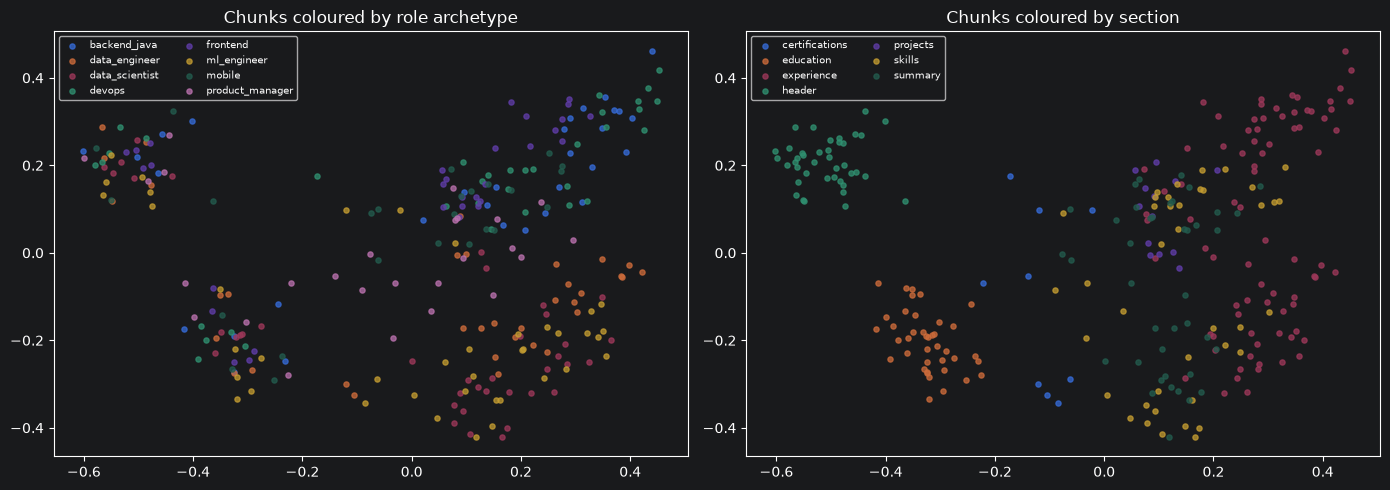

In [24]:
# Visualise the chunk embedding space (PCA), coloured by candidate archetype
from sklearn.decomposition import PCA
g = rag.collection.get(include=["embeddings", "metadatas"])
X = np.array(g["embeddings"]); fn2arch = {k: v["archetype"] for k, v in truth["resumes"].items()}
arch = [fn2arch[Path(m["resume_path"]).name] for m in g["metadatas"]]
sec = [m["section"] for m in g["metadatas"]]
Z = PCA(2, random_state=0).fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a in sorted(set(arch)):
    i = [k for k, x in enumerate(arch) if x == a]; ax[0].scatter(Z[i, 0], Z[i, 1], s=14, label=a, alpha=.75)
ax[0].legend(fontsize=7, ncol=2); ax[0].set_title("Chunks coloured by role archetype")
for s_ in sorted(set(sec)):
    i = [k for k, x in enumerate(sec) if x == s_]; ax[1].scatter(Z[i, 0], Z[i, 1], s=14, label=s_, alpha=.75)
ax[1].legend(fontsize=7, ncol=2); ax[1].set_title("Chunks coloured by section")
plt.tight_layout(); plt.show()

## 5. Semantic search: a single job description end to end
Output follows the required JSON schema (plus extra diagnostic fields).

In [25]:
matcher = JobMatcher(rag)
jd_text = (Path(DATA) / "job_descriptions" / "jd_01_senior_ml_engineer.txt").read_text()
res = matcher.match(jd_text, top_k=10)
print(json.dumps(res["parsed_requirements"], indent=1))
tbl = pd.DataFrame([{"rank": m["rank"], "candidate": m["candidate_name"], "score": m["match_score"],
                     "yrs": m["experience_years"], "matched_skills": ", ".join(m["matched_skills"][:5]),
                     "missing": ", ".join(m["missing_required_skills"])} for m in res["top_matches"]])
display(tbl)
print("Filtered out by must-haves:", len(res["filtered_out"]), "| latency:", res["meta"]["latency_ms"], "ms")
print("\nTop-1 in required output format:")
top1 = {k: res["top_matches"][0][k] for k in ["candidate_name", "resume_path", "match_score", "matched_skills", "relevant_excerpts", "reasoning"]}
print(json.dumps({"job_description": jd_text[:80] + "...", "top_matches": [top1]}, indent=2)[:2200])

{
 "title": "Senior Machine Learning Engineer",
 "required_skills": [
  "Python",
  "Machine Learning",
  "PyTorch",
  "TensorFlow",
  "AWS",
  "Docker"
 ],
 "preferred_skills": [
  "LLMs",
  "RAG",
  "MLOps",
  "Spark",
  "Kubernetes"
 ],
 "must_haves": [
  "5+ years Python",
  "3+ years Machine Learning",
  "bachelor degree or higher"
 ]
}


,rank,candidate,score,yrs,matched_skills,missing
0,1,Arjun Bello,87,10.5,"Python, Machine Learning, PyTorch, TensorFlow, AWS",Docker
1,2,Ethan Hassan,83,8.3,"Python, Machine Learning, PyTorch, TensorFlow, Docker",AWS
2,3,Amara Nair,78,9.8,"Python, Machine Learning, PyTorch, LLMs, MLOps","AWS, Docker"
3,4,Aarav Reddy,58,10.3,"Python, Machine Learning, Spark","PyTorch/TensorFlow, AWS, Docker"
4,5,Zainab Chen,52,7.0,"Python, Machine Learning, Spark","PyTorch/TensorFlow, AWS, Docker"


Filtered out by must-haves: 35 | latency: 812.8 ms

Top-1 in required output format:
{
  "job_description": "Senior Machine Learning Engineer\n\nAbout the role\nWe build recommendation and ran...",
  "top_matches": [
    {
      "candidate_name": "Arjun Bello",
      "resume_path": "resumes/06_arjun_bello.txt",
      "match_score": 87,
      "matched_skills": [
        "Python",
        "Machine Learning",
        "PyTorch",
        "TensorFlow",
        "AWS",
        "RAG"
      ],
      "relevant_excerpts": [
        "[experience] Machine Learning Engineer | Cobalt Cloud | May 2016 - Jan 2024 - Led code reviews and onboarding for 8 new hires working with machine learning. - Built feature engineering workflows with PyTorch and AWS shared across 8 product teams. - Day-to-day toolkit: Python.",
        "[experience] Senior ML Engineer | Helio Analytics | Jan 2024 - Present - Built feature engineering workflows with retrieval-augmented generation and TensorFlow shared across 7 product t

### Must-have filtering: who was excluded and why?

In [26]:
pd.DataFrame([{"candidate": f["candidate_name"], "reason": "; ".join(f["reasons"])} for f in res["filtered_out"]]).head(12)

,candidate,reason
0,Arjun Haddad,Python: 0 yrs < required 5; Machine Learning: 0 yrs < required 3
1,Arjun Patel,Python: 0 yrs < required 5; Machine Learning: 0 yrs < required 3
2,Arjun Silva,Python: 0 yrs < required 5; Machine Learning: 0 yrs < required 3
3,Carlos Petrov,Python: 2.2 yrs < required 5; Machine Learning: 0 yrs < required 3
4,Daniel Khan,Python: 1.8 yrs < required 5; Machine Learning: 1.8 yrs < required 3
5,Diego Iyer,Python: 2.3 yrs < required 5; Machine Learning: 2.3 yrs < required 3
6,Divya Kim,Python: 0 yrs < required 5; Machine Learning: 0 yrs < required 3
7,Fatima Hassan,Python: 4 yrs < required 5
8,Grace Fernandez,Python: 3.8 yrs < required 5; Machine Learning: 0 yrs < required 3
9,Grace Petrov,Python: 4.4 yrs < required 5; Machine Learning: 2.4 yrs < required 3


In [27]:
# Custom must-have override + the "no qualified candidate" edge case
r2 = matcher.match(jd_text, top_k=5, must_haves={"skills": {"Python": 8}})
print("Python 8+ yrs ->", [(m["candidate_name"], m["match_score"]) for m in r2["top_matches"]])
r3 = matcher.match(jd_text, top_k=5, must_haves={"min_total_years": 25})
print("25+ yrs total ->", len(r3["top_matches"]), "matches;", len(r3["filtered_out"]), "filtered out")
# soft mode: nobody removed, failures are penalised x0.6 and flagged
r4 = matcher.match(jd_text, top_k=10, strict=False)
print("soft mode flagged:", sum(bool(m["must_have_failures"]) for m in r4["top_matches"]), "of top 10")

Python 8+ yrs -> [('Arjun Bello', 87), ('Ethan Hassan', 83), ('Amara Nair', 78), ('Aarav Reddy', 58)]
25+ yrs total -> 0 matches; 40 filtered out
soft mode flagged: 5 of top 10


## 6. Retrieval experiments

Ground truth relevance per (JD, resume): **2** = right role *and* truly satisfies the must-haves (binary "relevant"); **1** = right role but fails must-haves, or secondary role that satisfies them; **0** otherwise.
Four modes are compared: semantic only, keyword (critical-skill coverage) only, hybrid (0.55 sem / 0.35 kw / 0.10 exp), and hybrid + must-have filters.

,P@5,R-Prec,R@10,MRR,nDCG@10,nDCG-bin@10,Hit@1
semantic only,0.525,0.604,1.0,0.875,0.924,0.861,0.750
keyword only,0.500,0.558,1.0,0.692,0.879,0.776,0.500
hybrid,0.525,0.604,1.0,0.775,0.898,0.803,0.625
hybrid + filters,0.550,1.000,1.0,1.000,0.836,1.000,1.000


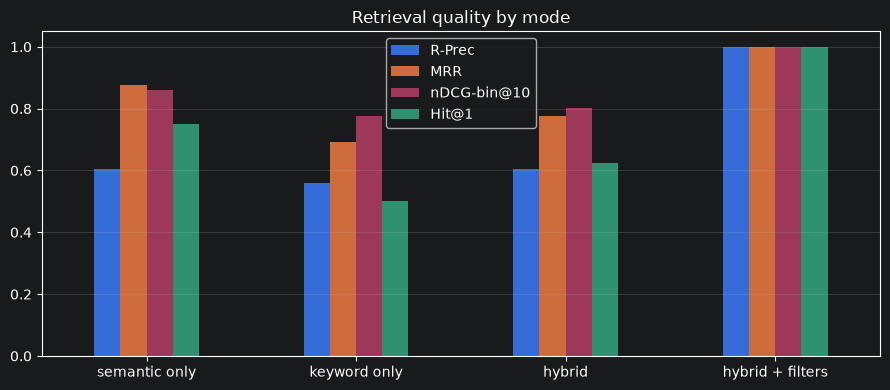

In [28]:
R = ev.evaluate_retrieval(matcher, DATA)
cols = ["P@5", "R-Prec", "R@10", "MRR", "nDCG@10", "nDCG-bin@10", "Hit@1"]
summary = pd.DataFrame({m: R[m]["mean"] for m in R}).T[cols].round(3)
display(summary)
summary[["R-Prec", "MRR", "nDCG-bin@10", "Hit@1"]].plot.bar(figsize=(9, 4), rot=0, ylim=(0, 1.05), title="Retrieval quality by mode")
plt.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

In [29]:
# per-JD breakdown (MRR / R-Prec) so weaknesses are not hidden by the mean
per = pd.DataFrame({m: {j[:12]: R[m]["per_jd"][j]["R-Prec"] for j in R[m]["per_jd"]} for m in R}).round(2)
display(per)

,semantic only,keyword only,hybrid,hybrid + filters
jd_01_senior,0.33,0.33,0.33,1.0
jd_02_data_s,1.00,0.80,1.00,1.0
jd_03_data_e,0.50,1.00,0.50,1.0
jd_04_backen,0.67,0.33,0.67,1.0
jd_05_fronte,1.00,1.00,1.00,1.0
jd_06_devops,0.67,0.33,0.67,1.0
jd_07_applie,0.00,0.00,0.00,1.0
jd_08_produc,0.67,0.67,0.67,1.0


### Weight sensitivity (hybrid)
Sweep the semantic weight; the remaining mass is split 78 / 22 between keyword and experience.

,R-Prec,MRR,nDCG-bin@10
w_semantic,,,
0.0,0.600,0.754,0.808
0.1,0.600,0.754,0.808
0.2,0.538,0.775,0.806
0.3,0.562,0.775,0.807
0.4,0.562,0.775,0.805
0.5,0.604,0.775,0.801
0.6,0.604,0.719,0.787
0.7,0.604,0.729,0.804
0.8,0.604,0.792,0.825


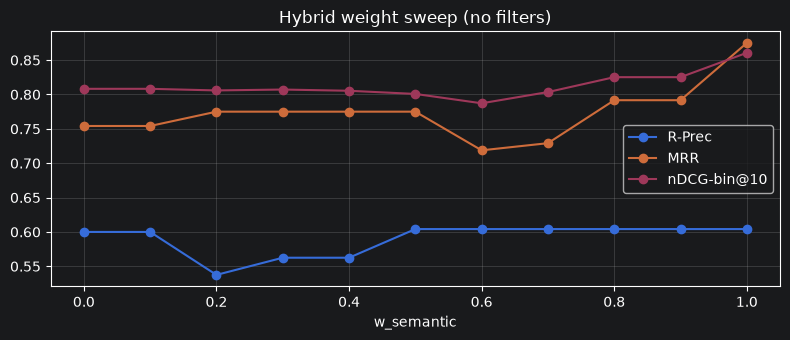

In [30]:
rows = []
for ws in np.linspace(0, 1, 11):
    w = Weights(ws, (1 - ws) * 0.78, (1 - ws) * 0.22)
    per_jd = []
    for slug, jd in truth["job_descriptions"].items():
        tx = (Path(DATA) / "job_descriptions" / f"{slug}.txt").read_text()
        grades = {f: ev.grade(t, jd) for f, t in truth["resumes"].items()}
        out = matcher.match(tx, top_k=10, weights=w, apply_filters=False)
        per_jd.append(ev.ranking_metrics([m["resume_path"] for m in out["top_matches"]], grades))
    mm = ev.mean_metrics(per_jd); rows.append({"w_semantic": round(ws, 1), **{k: mm[k] for k in ["R-Prec", "MRR", "nDCG-bin@10"]}})
sw = pd.DataFrame(rows).set_index("w_semantic"); display(sw.round(3))
sw.plot(figsize=(8, 3.5), marker="o", title="Hybrid weight sweep (no filters)"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Chunk-level vs. candidate-level: which sections drive the match?

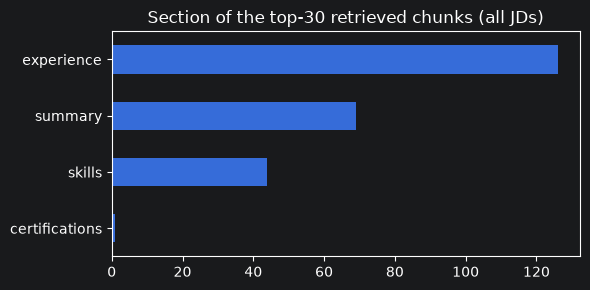

In [31]:
from collections import Counter
cnt = Counter()
for slug in truth["job_descriptions"]:
    tx = (Path(DATA) / "job_descriptions" / f"{slug}.txt").read_text()
    for h in matcher.rag.search_chunks(tx, k=30)["metadatas"][0]:
        cnt[h["section"]] += 1
pd.Series(cnt).sort_values().plot.barh(figsize=(6, 3), title="Section of the top-30 retrieved chunks (all JDs)")
plt.tight_layout(); plt.show()

## 7. Latency and scaling

In [32]:
lat = ev.evaluate_latency(matcher, DATA)
print(json.dumps(lat, indent=1))
print("Ingestion:", stats)

{
 "queries": 120,
 "end_to_end_ms": {
  "mean": 11.050074325369982,
  "p50": 9.48179152328521,
  "p95": 17.315958411199972,
  "max": 75.11462492402643
 },
 "jd_embedding_ms": {
  "mean": 5.74033572532547,
  "p95": 9.466199937742203
 }
}
Ingestion: {'resumes': 40, 'chunks': 262, 'embedder': 'st-all-MiniLM-L6-v2', 'parse_seconds': 0.183, 'embed_seconds': 3.251, 'total_seconds': 3.604}


,resumes,chunks,ingest_s,query_p50_ms,query_p95_ms
0,40,262,0.8,10.2,12.1
1,200,1310,2.0,14.2,17.8
2,400,2620,3.9,13.9,20.9
3,1000,6550,10.9,20.8,30.9


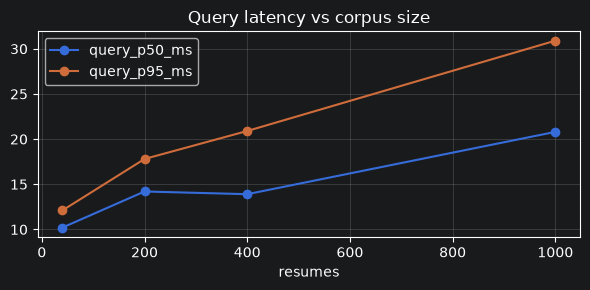

In [33]:
# Scaling: replicate the 40 resumes to 200 / 400 / 1000 files and re-measure
tmp = Path(tempfile.mkdtemp()); src = list_resume_files(Path(DATA) / "resumes")
texts = [(Path(DATA) / "job_descriptions" / f"{s}.txt").read_text() for s in truth["job_descriptions"]]
rows = []
for mult in [1, 5, 10, 25]:
    d = tmp / f"x{mult}" / "resumes"; d.mkdir(parents=True)
    for k in range(mult):
        for p in src: shutil.copy(p, d / f"{p.stem}_copy{k}{p.suffix}")
    r_ = ResumeRAG(str(tmp / f"db{mult}"), BACKEND, embedder=rag.embedder)
    st_ = r_.ingest_directory(str(d), reset=True); m_ = JobMatcher(r_); m_.match(texts[0])
    ts = []
    for _ in range(3):
        for t in texts:
            t0 = time.perf_counter(); m_.match(t); ts.append((time.perf_counter() - t0) * 1000)
    rows.append({"resumes": st_["resumes"], "chunks": st_["chunks"], "ingest_s": st_["total_seconds"],
                 "query_p50_ms": np.percentile(ts, 50), "query_p95_ms": np.percentile(ts, 95)})
sc = pd.DataFrame(rows).round(1); display(sc)
sc.plot(x="resumes", y=["query_p50_ms", "query_p95_ms"], marker="o", figsize=(6, 3), title="Query latency vs corpus size")
plt.grid(alpha=.3); plt.tight_layout(); plt.show(); shutil.rmtree(tmp, ignore_errors=True)

## 8. Error analysis

In [34]:
# For every JD (hybrid + filters) show where non-relevant candidates ranked in the top 5
for slug, jd in truth["job_descriptions"].items():
    tx = (Path(DATA) / "job_descriptions" / f"{slug}.txt").read_text()
    out = matcher.match(tx, top_k=5)
    line = []
    for m in out["top_matches"]:
        f = Path(m["resume_path"]).name; line.append(f'{m["candidate_name"].split()[0]}({m["match_score"]},g{ev.grade(truth["resumes"][f], jd)})')
    print(f"{slug[:28]:<28}", " ".join(line))
print("\n(g2 = truly relevant, g1 = partially, g0 = wrong role)")

jd_01_senior_ml_engineer     Arjun(87,g2) Ethan(83,g2) Amara(78,g2) Aarav(58,g1) Zainab(52,g1)
jd_02_data_scientist         Liam(91,g2) Aarav(90,g2) Priya(88,g2) Zainab(87,g2) Grace(86,g2)
jd_03_data_engineer          Samuel(96,g2) Priya(83,g2) Aarav(54,g0)
jd_04_backend_java_engineer  Marta(95,g2) Mei(93,g2) Pavel(76,g2)
jd_05_frontend_engineer      Omar(98,g2) Lucía(94,g2)
jd_06_devops_sre             Grace(95,g2) Hiroshi(89,g2) Zainab(87,g2)
jd_07_applied_llm_engineer   Amara(77,g2)
jd_08_product_manager        Layla(98,g2) Arjun(92,g2) Hiroshi(86,g2)

(g2 = truly relevant, g1 = partially, g0 = wrong role)


In [35]:
# Without filters, which wrong-role / under-qualified candidates sneak into the top 10 (hybrid)?
fp = []
for slug, jd in truth["job_descriptions"].items():
    tx = (Path(DATA) / "job_descriptions" / f"{slug}.txt").read_text()
    for m in matcher.match(tx, top_k=10, apply_filters=False)["top_matches"][:5]:
        f = Path(m["resume_path"]).name; g_ = ev.grade(truth["resumes"][f], jd)
        if g_ < 2: fp.append({"jd": slug[:18], "candidate": m["candidate_name"], "score": m["match_score"], "grade": g_,
                              "role": truth["resumes"][f]["archetype"], "yrs": truth["resumes"][f]["total_years"]})
display(pd.DataFrame(fp).head(15)); print(len(fp), "non-relevant results in top-5 across 8 JDs without filtering")

,jd,candidate,score,grade,role,yrs
0,jd_01_senior_ml_en,Sofia Khan,93,1,ml_engineer,3.7
1,jd_01_senior_ml_en,Fatima Hassan,85,1,ml_engineer,4.0
2,jd_01_senior_ml_en,Daniel Khan,79,1,ml_engineer,1.8
3,jd_03_data_enginee,Grace Fernandez,93,1,data_engineer,3.8
4,jd_03_data_enginee,Carlos Petrov,86,1,data_engineer,2.2
5,jd_03_data_enginee,Hannah Moreau,86,1,data_engineer,3.6
6,jd_04_backend_java,Divya Kim,94,1,backend_java,4.3
7,jd_04_backend_java,Arjun Patel,80,1,backend_java,1.8
8,jd_05_frontend_eng,Noah Ali,91,1,frontend,5.0
9,jd_05_frontend_eng,Samuel Mensah,89,1,frontend,11.7


19 non-relevant results in top-5 across 8 JDs without filtering


## 9. Findings and limitations

*(Numbers below are from the run saved in this notebook, with the backend printed at the top. Re-run with `EMBED_BACKEND=st` for MiniLM numbers; conclusions about the embedder should be re-checked then.)*

* **Hybrid is modestly better than either signal alone, not dramatically.** Hybrid had the best binary nDCG, tied semantic-only on R-Precision, and beat keyword-only on R-Precision. Keyword-only is competitive when the JD's wording matches resumes (Data Engineer) and collapses when it does not (LLM JD: 0.0 R-Precision), which is the case for semantic search. The weight sweep is flat for semantic weight between 0.4 and 0.9, so the exact weights matter little as long as semantics carries more than ~40%.
* **Hard must-have filters are the biggest quality lever.** All 19 non-relevant results in the unfiltered top-5 were the *right role but under-qualified* (e.g. 2-4 years against a 5+ requirement); none were the wrong role. Embeddings and skill coverage cannot distinguish seniority; the filter can. With filters, R-Precision, MRR and binary nDCG are all 1.0 on this dataset, and the filter agrees with ground truth on every candidate (precision = recall = 1.0). Graded nDCG@10 drops because "right role, fails must-have" candidates (grade 1) are deliberately excluded, which is the intended behaviour of a hard filter, not a ranking regression.
* **Section-aware chunking** keeps one job per chunk, so excerpts and "matched sections" in the reasoning are interpretable.
* **Latency** grows roughly linearly with corpus size but stays interactive (tens of ms per query up to 1,000 resumes on a laptop-class CPU; ingestion is dominated by parsing and embedding).

**Limitations.** (1) The dataset is synthetic and clean (consistent headings, dates, no tables or columns), so absolute numbers are optimistic; real resumes need layout handling / OCR. (2) Parsing of "N+ years of X" and "A or B" is rule-based; an LLM structured-extraction step would be more robust. (3) Per-skill years come from the dates of jobs that mention the skill, using a fixed skill taxonomy. (4) Semantic scores are min-max normalised per query, so the 0-100 scores are relative to the candidate pool, not absolute. (5) Ground truth labels were produced by the same generator that wrote the resumes, so extraction accuracy is an upper bound. (6) Hiring is a high-stakes domain: do not match on protected attributes, audit for bias, and keep a human in the loop.